# Laboratorio 9 - Deep Learning

- Juan Solís - 23720
- Victor Pérez - 23731
- Diego Flores - 23714
- Nils Muralles - 23727
- Isabella Recinos - 23003

## Task 1

### Task 1.1

Se descarga Fashion-MNIST, se escalan los píxeles a [0,1] y se separan los últimos 5 000 ejemplos de entrenamiento como validación. Se fijan la semilla y los hiperparámetros del enunciado.

In [1]:
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets

# Semilla
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

# Configuración
batch_size = 128
latent_dim = 2
epochs = 20
lr = 1e-3
beta_values = [0.1, 1.0, 10.0]

# Descarga y escalado a [0,1]
data = datasets.FashionMNIST("data", train=True, download=True)
X = (data.data.float() / 255.0).view(-1, 784)
Y = data.targets

# Separación train / validación (últimos 5 000)
x_train, y_train = X[:-5000].to(device), Y[:-5000]
x_val, y_val = X[-5000:].to(device), Y[-5000:]
print(x_train.shape, x_val.shape, "| semilla:", SEED, "| device:", device)

100%|██████████| 26.4M/26.4M [00:05<00:00, 5.11MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 144kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.30MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 7.48MB/s]


torch.Size([55000, 784]) torch.Size([5000, 784]) | semilla: 42 | device: cpu


### Task 1.2

Se implementa un VAE completamente conectado (misma arquitectura para todos los β) con reparametrización, KL en forma cerrada y pérdida ℒβ escritas a mano. Se entrena un modelo por cada β y se grafican las curvas de validación de reconstrucción y KL por época.

beta=0.1: recon=19.92, KL=8.40
beta=1.0: recon=21.30, KL=5.25
beta=10.0: recon=36.48, KL=1.73


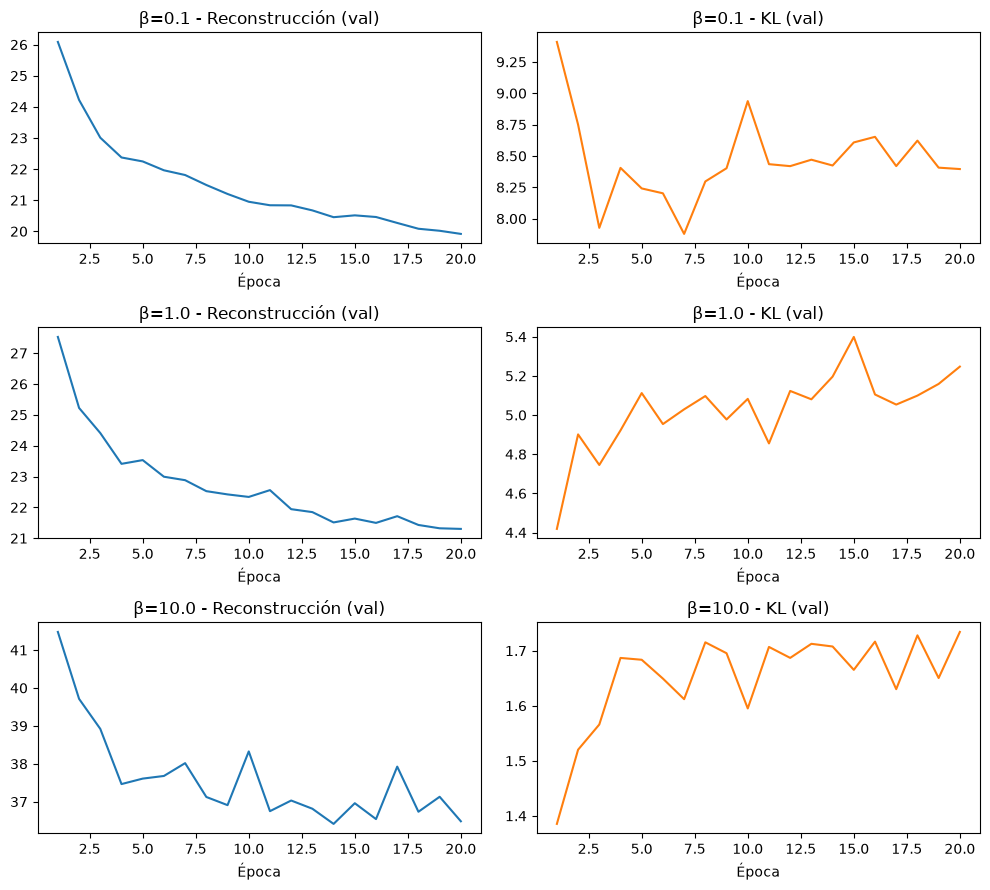

In [2]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.dec = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 512), nn.ReLU(),
                                 nn.Linear(512, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = reparameterize(mu, logvar)
        return self.dec(z), mu, logvar

# a. Reparametrización z = mu + sigma * eps
def reparameterize(mu, logvar):
    eps = torch.randn_like(mu)
    return mu + torch.exp(0.5 * logvar) * eps

# b. KL en forma cerrada entre N(mu, diag(sigma^2)) y N(0, I), sumada sobre dimensiones latentes
def kl_closed(mu, logvar):
    return 0.5 * torch.sum(mu**2 + torch.exp(logvar) - 1 - logvar, dim=1)

# c. Pérdida por imagen: error cuadrático sumado sobre 784 píxeles + beta * KL
def vae_loss(x, x_hat, mu, logvar, beta):
    recon = torch.sum((x - x_hat) ** 2, dim=1)
    kl = kl_closed(mu, logvar)
    return recon + beta * kl, recon, kl

# Entrenamiento de un modelo por beta
models, history = {}, {}
for beta in beta_values:
    torch.manual_seed(SEED)
    model = VAE(latent_dim).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"val_recon": [], "val_kl": []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(x_train.size(0), device=device)
        for i in range(0, x_train.size(0), batch_size):
            xb = x_train[perm[i:i + batch_size]]
            x_hat, mu, logvar = model(xb)
            loss, _, _ = vae_loss(xb, x_hat, mu, logvar, beta)
            opt.zero_grad()
            loss.mean().backward()
            opt.step()
        # Validación por época
        model.eval()
        with torch.no_grad():
            x_hat, mu, logvar = model(x_val)
            _, recon, kl = vae_loss(x_val, x_hat, mu, logvar, beta)
        hist["val_recon"].append(recon.mean().item())
        hist["val_kl"].append(kl.mean().item())
    models[beta], history[beta] = model, hist
    print(f"beta={beta}: recon={hist['val_recon'][-1]:.2f}, KL={hist['val_kl'][-1]:.2f}")

# Curvas de validación por beta
fig, axs = plt.subplots(len(beta_values), 2, figsize=(10, 9))
for r, beta in enumerate(beta_values):
    axs[r, 0].plot(range(1, epochs + 1), history[beta]["val_recon"])
    axs[r, 0].set_title(f"β={beta} - Reconstrucción (val)")
    axs[r, 1].plot(range(1, epochs + 1), history[beta]["val_kl"], color="C1")
    axs[r, 1].set_title(f"β={beta} - KL (val)")
    for a in axs[r]:
        a.set_xlabel("Época")
plt.tight_layout()
plt.show()